In [ ]:
from math import floor, ceil, sqrt, pi, sin, cos
import matplotlib.pyplot as plt

In [379]:
# Make list for best solutions
best = [{'n_squares': i,
         'box_size': (s:=ceil(sqrt(i))),
         'method': 'BASE' if i else 'IGNORE', 
         'score': s/sqrt(i)-1 if i else 0}
        for i in range(1001)]

In [380]:
# Mark unimprovable solutions - square, square-1, square-2
for i in range(1001):
    if best[i]['method']=='BASE' and sqrt(i)%1==0:
        best[i]['method'] = 'SQUARE'
    elif best[i]['method']=='BASE' and sqrt(i+1)%1==0:
        best[i]['method'] = 'SQUARE-1'
    elif best[i]['method']=='BASE' and sqrt(i+2)%1==0:
        best[i]['method'] = 'SQUARE-2'

In [381]:
# Capture base scores
scores_base = [i['score'] for i in best[1:]]
sum(scores_base)

28.937669916550586

In [ ]:
# Patterns with a rectangle of squares at 45° in the middle
oppdict = dict(zip((z:=['nw', 'ne', 'se', 'sw', 'nw', 'ne']),z[2:]))
sign = lambda x: (x > 0) - (x < 0)

# Loop over combinations of center shape dimensions
for nw_side in range(1,44):
    for ne_side in range(1,nw_side+1):
        # Rows in outside corners
        combos = [{'nw':nw,'se':se,'ne':ne,'sw':sw}
                  for nw in[f(nw_side/sqrt(2)) for f in[floor,ceil]]
                  for se in[f(nw_side/sqrt(2)) for f in[floor,ceil]]
                  for ne in[f(ne_side/sqrt(2)) for f in[floor,ceil]]
                  for sw in[f(ne_side/sqrt(2)) for f in[floor,ceil]]
                  if nw>=se>=ne>=sw]
        for c in combos:
            # Get N squares for this scenario - stop if >1000 or # corner squares prevent solution
            n_squares = nw_side * ne_side + sum([i*(i+1)//2 for i in c.values()])
            if (n_squares > 1000 
                or max([sum([c[j] for j in c if i in j]) 
                        for i in 'nsew']) >= ceil(sqrt(n_squares))):
                continue
            # Calculate smallest bounding box size, required positioning of middle square
            lims = {i: ([nw_side,ne_side][i in['nw','se']]/2)
                    +(((c[i]+1)*sqrt(2)/2) if c[i] else 0.5) 
                    for i in c}
            coords_raw = {i: [[1,-1][j in i]*sqrt((lims[i]**2)/2) 
                              for j in 'nw'] 
                          for i in lims}
            s = ['nw','se'] if (lims['nw']+lims['se'])/sum(lims.values()) >= 0.5 else ['ne','sw']
            coords_adj = {i:[[coords_raw[k][j] 
                              for k in coords_raw 
                              if i[j] in k and k in s][0] 
                             for j in [0,1]]
                          for i in coords_raw}
            mid_sq_offset = [sum([coords_adj[j][i]-coords_raw[j][i] 
                                  for j in ['nw', 'ne']]) 
                             for i in [0,1]]
            box_size = coords_adj['sw'][0]-coords_adj['nw'][0]

            
            # offsets_raw = {i: [sqrt((lims[i]**2)/2) for j in '01'] for i in lims}
            # offsets_adj = {i: [[offsets_raw[(i[j]+oppdict[i][1-j])[::1-2*j]][j], offsets_raw[i][j]]
            #                    [sum([lims[i], lims[oppdict[i]]]) / sum(lims.values()) >= 0.5]
            #                    for j in[0,1]]
            #                for i in offsets_raw}
            # mid_sq_offset = [sum([max(offsets_raw[k][i]-offsets_adj[k][i],0) 
            #                       for k in offsets_raw 
            #                       if j in k])
            #                  for i,j in enumerate('nw')]
            
            # box_size = [*z][0]
            
            # If solution improves on existing base for N squares, update best dict
            if box_size < best[n_squares]['box_size']:
                best[n_squares]['box_size'] = box_size
                best[n_squares]['method'] = '45DEG'
                center_pt = [box_size/2+i for i in mid_sq_offset]
                best[n_squares]['params'] = {'nw_side': nw_side, 
                                             'ne_side': ne_side, 
                                             'corner_sq': c, 
                                             'center_pt': center_pt}
                best[n_squares]['score'] = box_size/sqrt(n_squares)-1
                
            # Test additional solutions made by adding full rows to base solution
            side_sq = {i:sum([c[j] for j in c if i in j]) for i in 'nsew'}
            exp_sides = [[*i][side_sq[i[1]]>side_sq[i[0]]] for i in ['ns','we']]
            exp_inc = sum([side_sq[i] for i in exp_sides])
            exp_rows = 1
            while True:
                # Add rows, update n_squares and box_size
                n_squares += exp_inc+1
                box_size += 1
                if n_squares > 1000:
                    break
                # If solution improves on existing base for N squares, update best dict
                if box_size < best[n_squares]['box_size']:
                    best[n_squares]['box_size'] = box_size
                    best[n_squares]['method'] = '45DEG-EXP'
                    center_pt = [round((i in 'nw')*exp_rows+j+k, 10) 
                                 for i,j,k in zip(exp_sides, offsets_adj['nw'], mid_sq_offset)]
                    
                                [box_size/2+i for i in mid_sq_offset]
                    best[n_squares]['params'] = {'nw_side': nw_side, 
                                                 'ne_side': ne_side,
                                                 'corner_sq': c, 
                                                 'exp': {i:exp_rows for i in exp_sides}, 
                                                 'center_pt': center_pt}
                    best[n_squares]['score'] = box_size/sqrt(n_squares)-1
                exp_inc += 2
                exp_rows += 1
        print(f"\rChecked ({nw_side}*{ne_side})", end='')               
                

Checked (43*43)

In [421]:
            # Calculate smallest bounding box size, required positioning of middle square
            lims = {i: ([nw_side,ne_side][i in['nw','se']]/2)
                    +(((c[i]+1)*sqrt(2)/2) if c[i] else 0.5) 
                    for i in c}
            offsets_raw = {i: [sqrt((lims[i]**2)/2) for j in '01'] for i in lims}
            offsets_adj = {i: [[offsets_raw[(i[j]+oppdict[i][1-j])[::1-2*j]][j], offsets_raw[i][j]]
                               [sum([lims[i], lims[oppdict[i]]]) / sum(lims.values()) >= 0.5]
                               for j in[0,1]]
                           for i in offsets_raw}

In [ ]:
coords_raw = {i: [[1,-1][j in i]*sqrt((lims[i]**2)/2) 
                  for j in 'nw'] 
              for i in lims}
s = ['nw','se'] if (lims['nw']+lims['se'])/sum(lims.values()) >= 0.5 else ['ne','sw']
coords_adj = {i:[[coords_raw[k][j] 
                  for k in coords_raw 
                  if i[j] in k and k in s][0] 
                 for j in [0,1]]
              for i in coords_raw}
mid_sq_offset = [sum([coords_adj[j][i]-coords_raw[j][i] 
                      for j in ['nw', 'ne']]) 
                 for i in [0,1]]
box_size = coords_adj['sw'][0]-coords_adj['nw'][0]

{'nw': [-15.303300858899107, -15.303300858899107],
 'se': [15.303300858899107, 15.303300858899107],
 'ne': [-15.303300858899107, 15.303300858899107],
 'sw': [15.303300858899107, -15.303300858899107]}

In [500]:
coords_adj

{'nw': [-15.303300858899107, -15.303300858899107],
 'se': [15.303300858899107, 15.303300858899107],
 'ne': [-15.303300858899107, 15.303300858899107],
 'sw': [15.303300858899107, -15.303300858899107]}

In [499]:
[box_size/2+i for i in mid_sq_offset]

[15.545941546018392, 15.060660171779821]

In [407]:
# Capture updated scores
scores_after_m1 = [i['score'] for i in best[1:]]
sum(scores_after_m1)

23.26114068295558

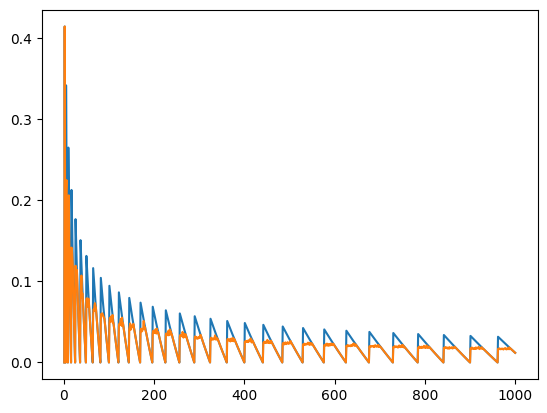

In [408]:
# Scores before and after
sqnum = [i['n_squares'] for i in best[1:]]
plt.plot(sqnum, scores_base)
plt.plot(sqnum, scores_after_m1)
plt.show()

In [409]:
def get_squares(sqdict):
    """
    Get square positioning info (y/x/angle) for specified solution.
    """
    k = sqdict['method']
    return {
        '45DEG': get_squares_45deg, 
        '45DEG-EXP': get_squares_45deg, 
        'BASE': get_squares_base, 
        'SQUARE': get_squares_base, 
        'SQUARE-1': get_squares_base, 
        'SQUARE-2': get_squares_base, 
    }[k](sqdict)
    
def get_squares_base(sqdict):
    """
    Generate square positioning info (y/x/angle) for base solution.
    Methods: 'BASE', 'SQUARE', 'SQUARE-1', 'SQUARE-2'
    """
    return [[i//sqdict['box_size']+0.5, i%sqdict['box_size']+0.5, 0.] 
            for i in range(sqdict['n_squares'])]

def get_squares_45deg(sqdict):
    """
    Generate square positioning info (y/x/angle) for solution based on a 
    central rectangle of squares rotated 45-degrees.
    Methods: '45DEG', '45DEG-EXP'
    """
    squares = []
    expdict = {i: sqdict['params'].get('exp',{}).get(i,0) for i in 'nswe'}
    cy,cx = sqdict['params']['center_pt']
    ne = sqdict['params']['ne_side']
    nw = sqdict['params']['nw_side']
    for c,nrows in sqdict['params']['corner_sq'].items():
        squares += [[y+yy+expdict[c[0]]+0.5 if c[0]=='n' 
                     else sqdict['box_size']-(y+yy+expdict[c[0]]+0.5),
                     x+xx+expdict[c[1]]+0.5 if c[1]=='w' 
                     else sqdict['box_size']-(x+xx+expdict[c[1]]+0.5),
                     0.]
                    for y in range(nrows)
                    for yy in range(0 if y else -expdict[c[0]], 1)
                    for x in range(nrows-y)
                    for xx in range(0 if x else -expdict[c[1]], 1)]
    squares += [[cy+((i-(ne-1)/2)*cos(pi/4))-((j-(nw-1)/2)*sin(pi/4)),
                 cx+((i-(ne-1)/2)*sin(pi/4))+((j-(nw-1)/2)*cos(pi/4)),
                 pi/4]
                for i in range(ne)
                for j in range(nw)]
    return sorted(squares)

def show_squares(squares):
    plt.subplots()[1].set_aspect('equal', adjustable='box')
    for i in squares:
        edges = [[x*sin(i[2])+y*cos(i[2])+i[0],
                  x*cos(i[2])-y*sin(i[2])+i[1]] 
                 for y,x in [[-0.5,-0.5],[-0.5,0.5],[0.5,0.5],[0.5,-0.5],[-0.5,-0.5]]]
        plt.plot(*zip(*edges), color='black')
    plt.show()

In [413]:
best[967]

{'n_squares': 967,
 'box_size': 31.606601717798213,
 'method': '45DEG-EXP',
 'score': 0.016399790319566954,
 'params': {'nw_side': 27,
  'ne_side': 15,
  'corner_sq': {'nw': 19, 'se': 19, 'ne': 11, 'sw': 10},
  'exp': {'n': 1, 'e': 1},
  'center_pt': [16.545941546, 15.3033008589]}}

951


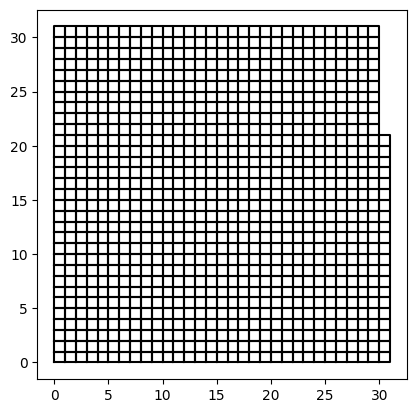


952


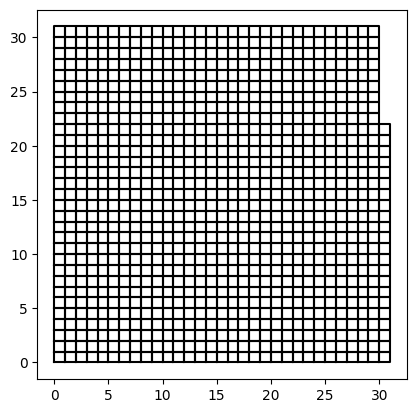


953


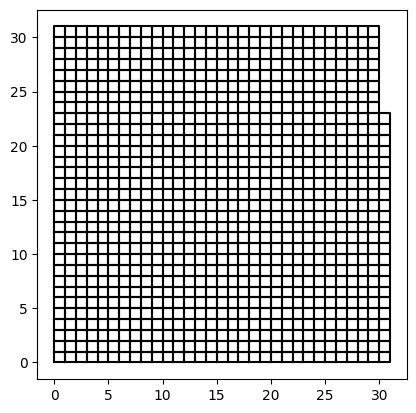


954


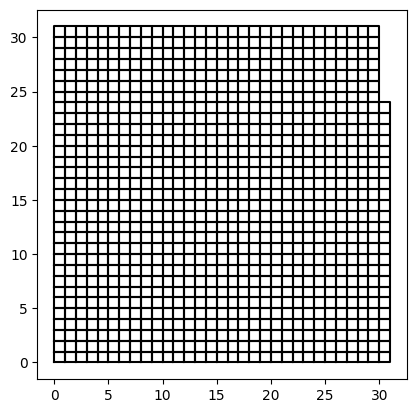


955


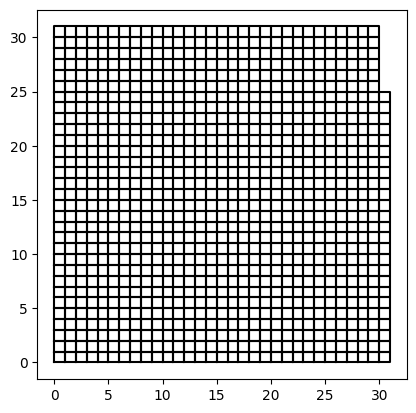


956


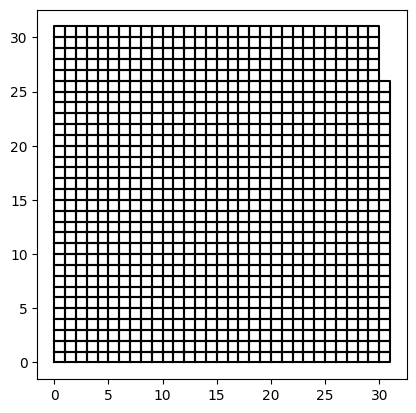


957


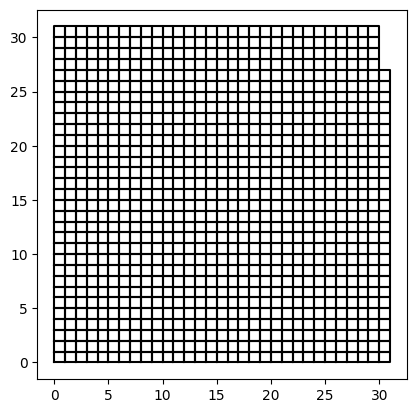


958


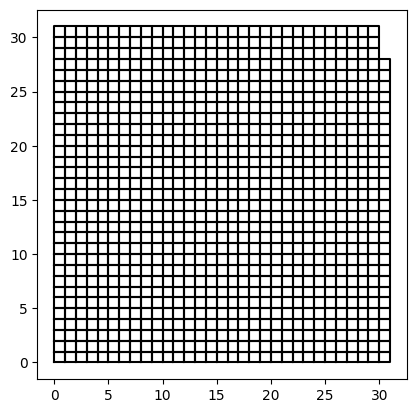


959


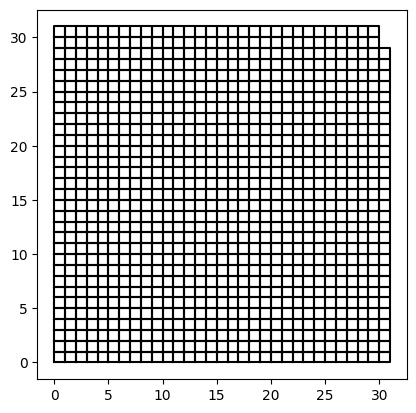


960


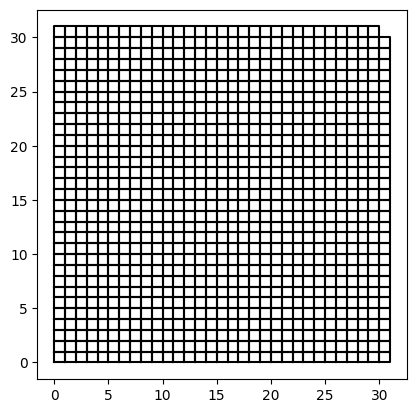


961


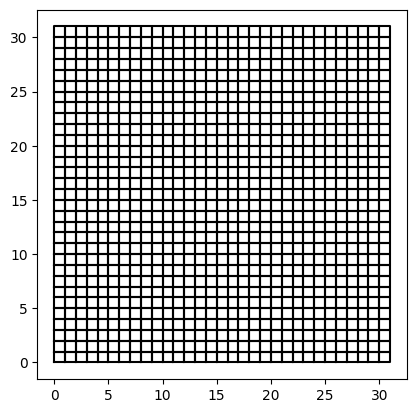


962


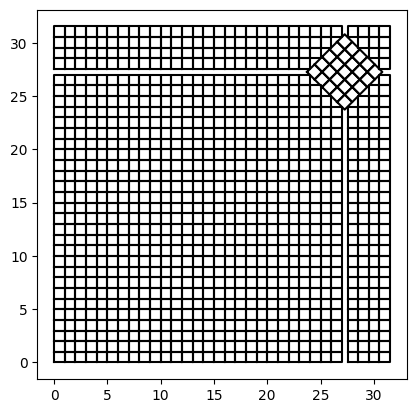


963


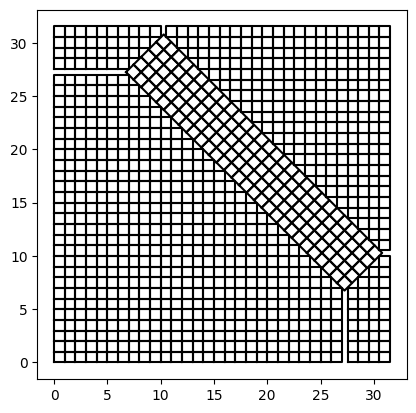


964


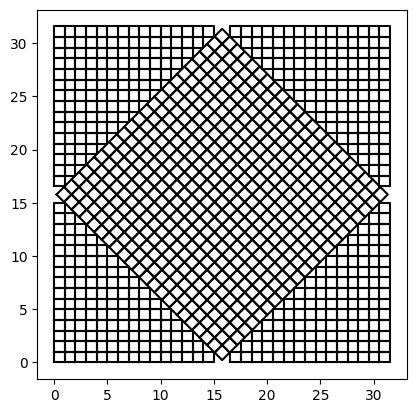


965


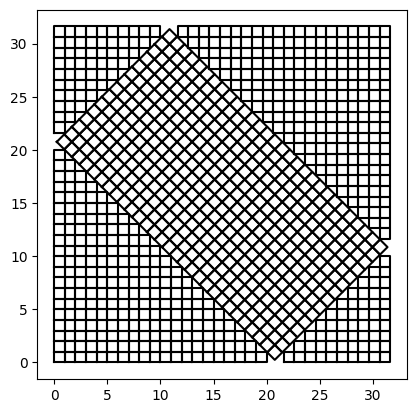


966


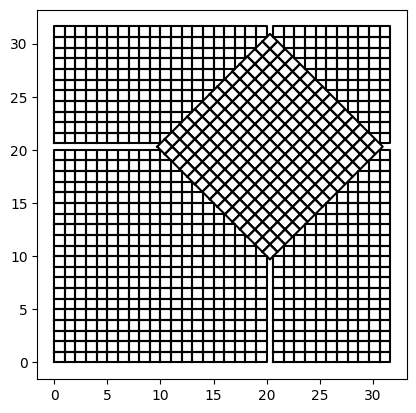


967


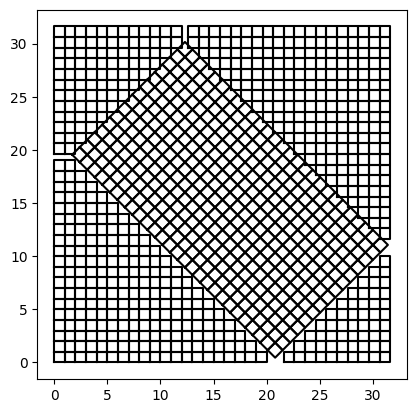


968


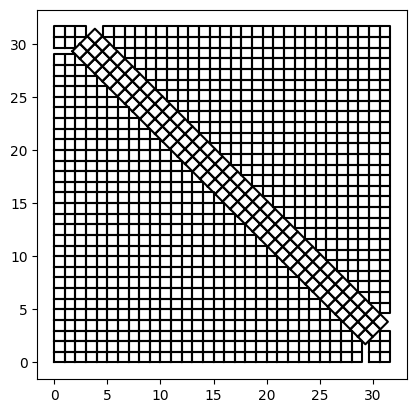


969


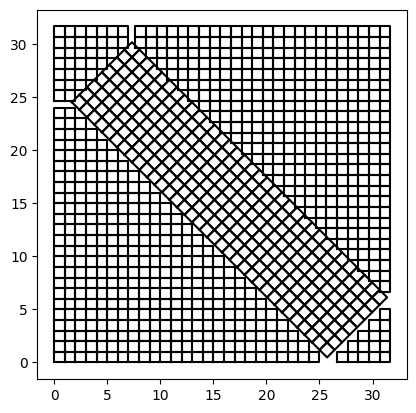


970


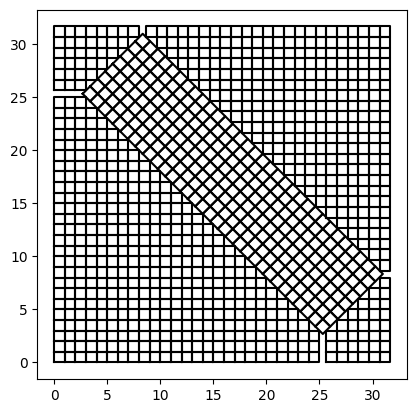


971


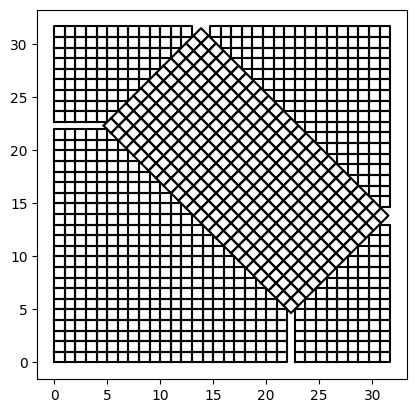


972


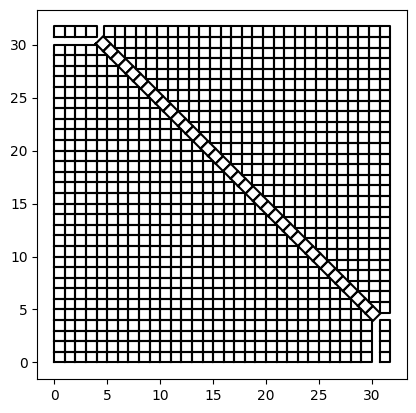


973


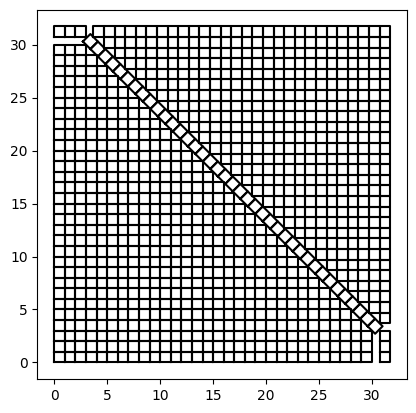


974


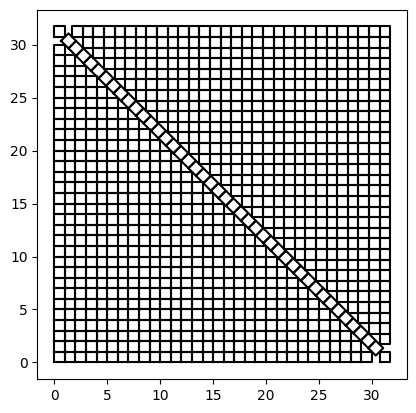


975


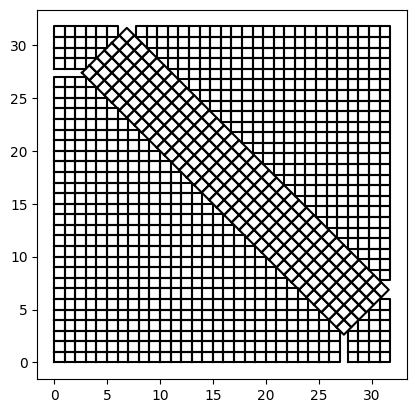


976


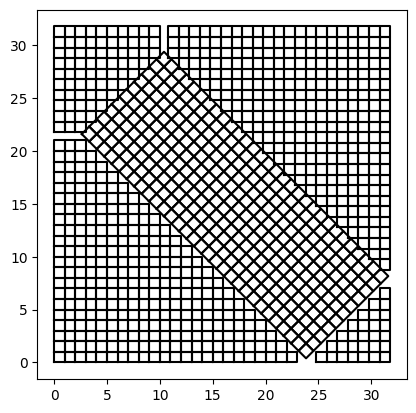


977


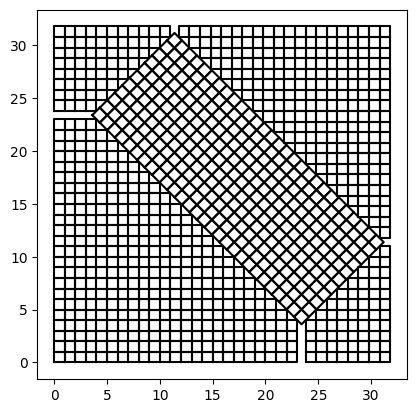


978


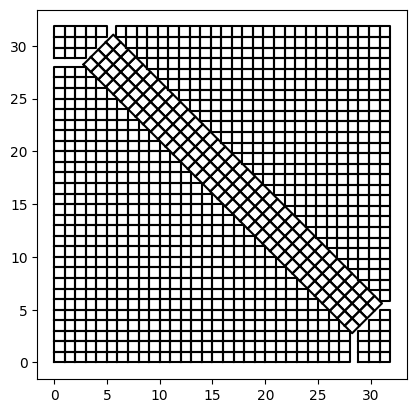


979


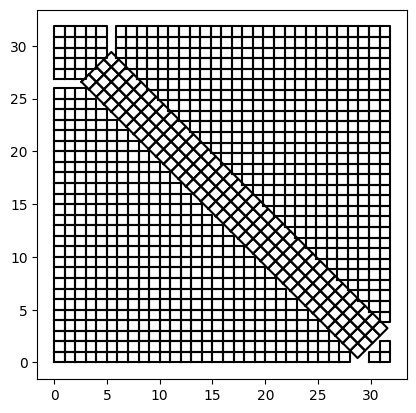


980


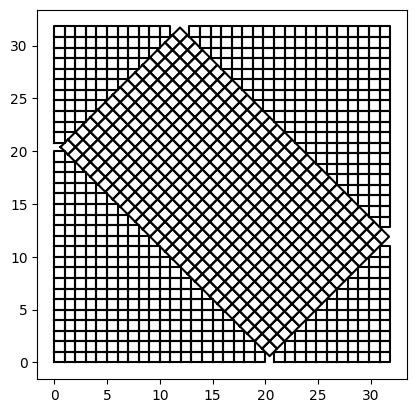


981


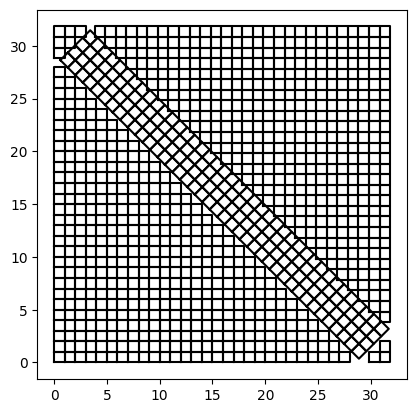


982


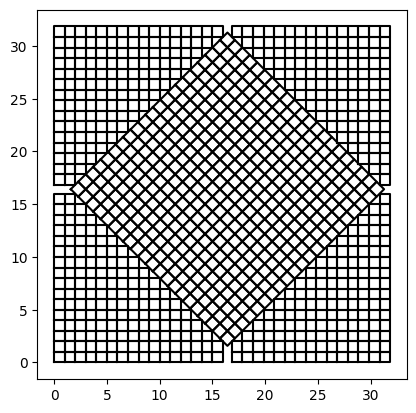


983


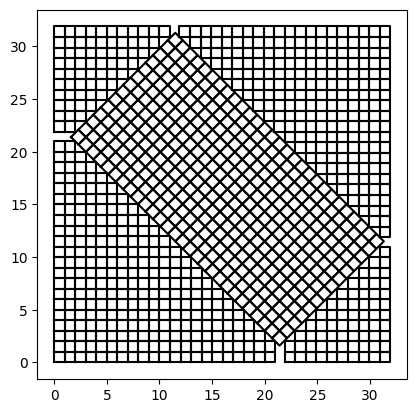


984


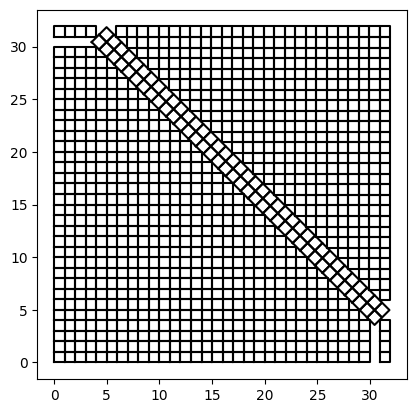


985


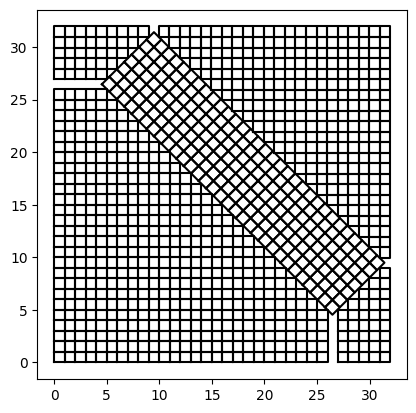


986


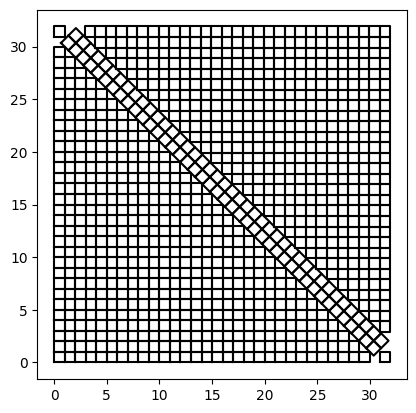


987


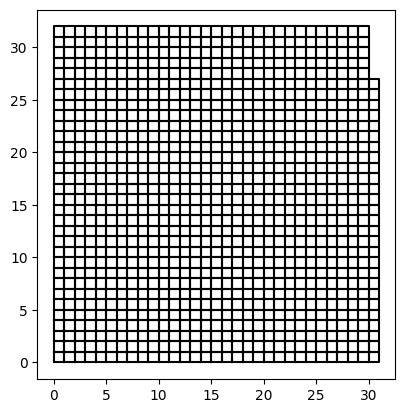


988


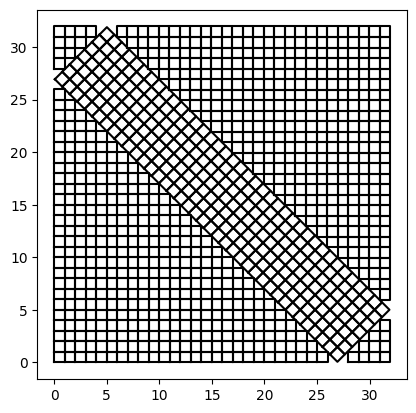


989


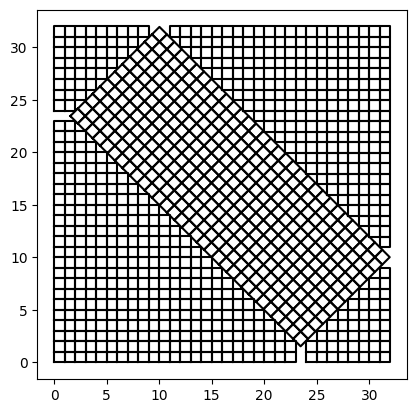


990


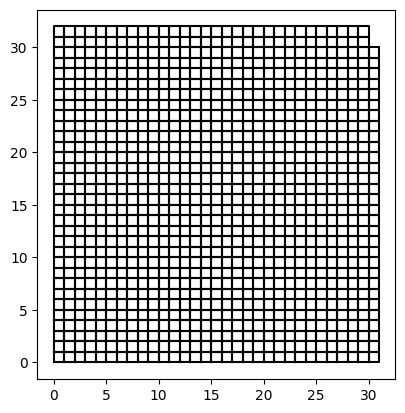


991


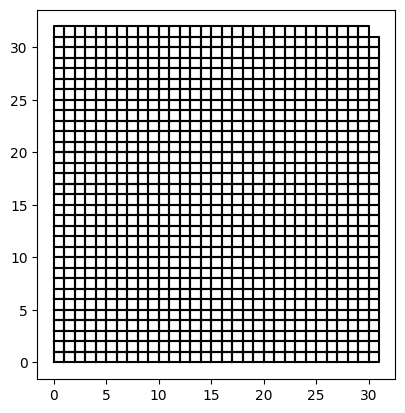


992


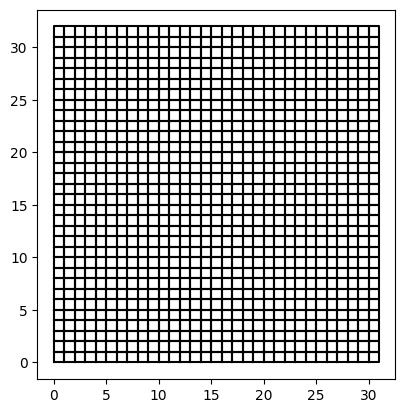


993


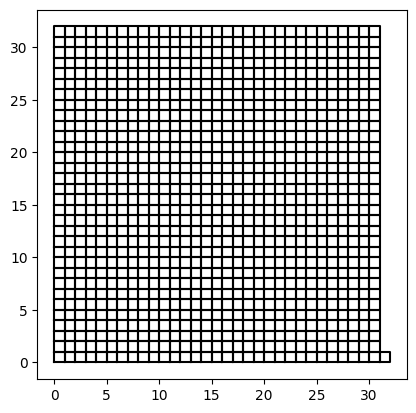


994


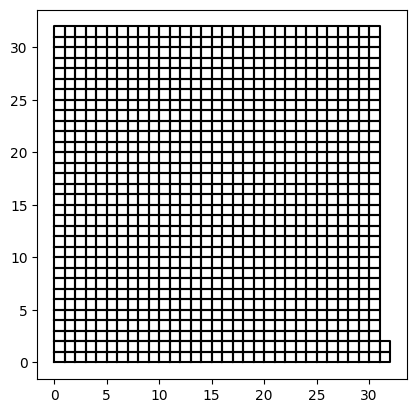


995


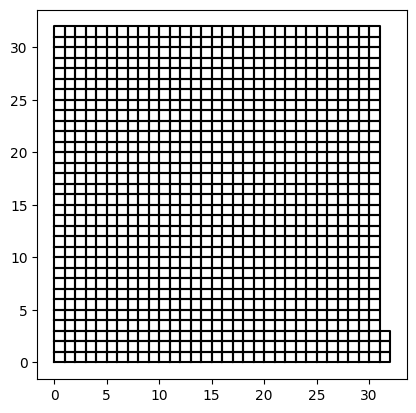


996


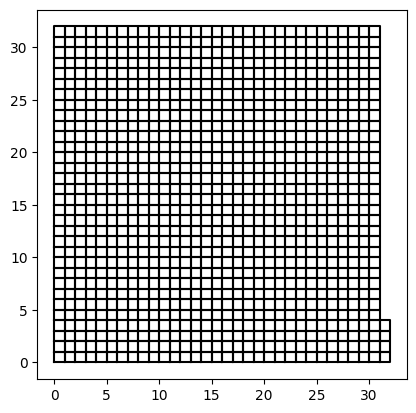


997


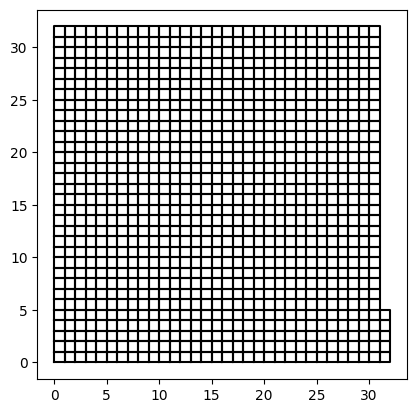


998


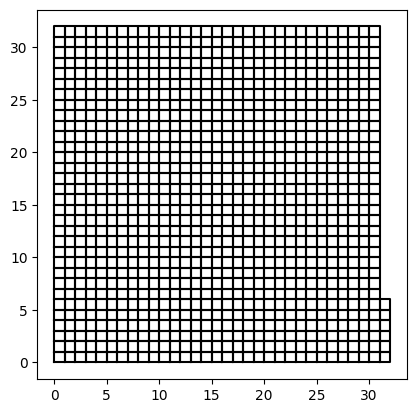


999


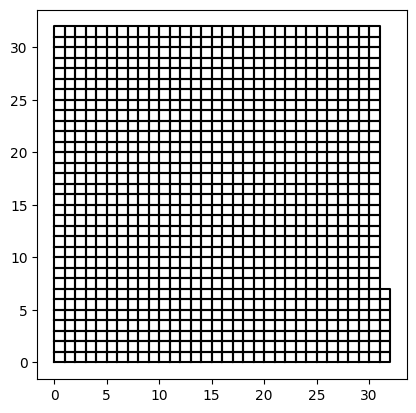


1000


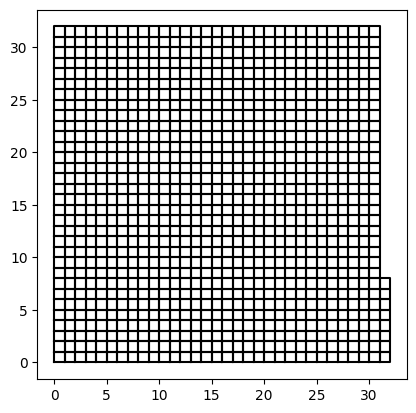

In [412]:
for i in best[951:1001]:
    print(i['n_squares'])
    show_squares(get_squares(i))
    print()